# 数値積分 ― integrate モジュール

## この章で学ぶこと

`integrate` モジュールには、定積分を計算する関数と、常微分方程式を解く関数があります。この章では、次の内容を例で確かめます。

* 定積分を数値的に計算する(`quad()`)
* 2 重積分、3 重積分(`dblquad()`、`tplquad()`)
* 常微分方程式を解く(`odeint()`、`solve_ivp()`)
* 質量-ばね-ダンパ系と PID 制御のシミュレーション
* 質点とばねで懸垂線をシミュレーションする
* 境界値問題を解く(`solve_bvp()`)

In [1]:
from matplotlib import pyplot as plt

import helper.matplotlib
import numpy as np
from scipy import integrate, optimize
from scipy.integrate import odeint

## 定積分を計算する

数値積分は定積分を数値的に求める方法で、図形の面積を計算するのにも使えます。例として、半径 1 の半円の面積を求めてみます。半円の面積は $\pi/2$ になるはずです。単位半円の曲線は $y=\sqrt{1-x^2}$ で、次の関数で表せます。

In [2]:
def half_circle(x):
    return (1 - x**2) ** 0.5

いちばん簡単な数値積分は、面積を細かい長方形に分けて足す方法です。x 軸の -1 から 1 までを 10000 等分して、長方形の面積を合計します。

In [3]:
N = 10000
x = np.linspace(-1, 1, N)
dx = x[1] - x[0]
y = half_circle(x)
2 * dx * np.sum(y)   # 半円の面積の 2 倍(円の面積)

np.float64(3.1415893269307373)

NumPy の `trapezoid()` を使うと、点を結んだ折れ線と x 軸の間の面積を計算できます。長方形で近似するより精度が上がります。

In [4]:
np.trapezoid(y, x) * 2

np.float64(3.141589326931597)

`integrate.quad()` を使うと、さらに正確な値が得られます。戻り値は (積分値, 誤差の推定値) のタプルです。

In [5]:
area_half, err = integrate.quad(half_circle, -1, 1)
area_half * 2

3.1415926535897967

## 多重積分

2 重積分は `quad()` を 2 回呼んでも計算できますが、`integrate.dblquad()` を使うと簡単です。3 重積分には `tplquad()` があります。

例として、単位半球の体積を計算します。半球面上の点 $(x,y,z)$ は $x^2 + y^2 + z^2 = 1$ を満たすので、次の関数で x, y から z が求まります。

In [6]:
def half_sphere(x, y):
    return (1 - x**2 - y**2) ** 0.5

xy 平面とこの半球の交わりは単位円です。したがって、x は -1 から 1 まで、y は $-\sqrt{1-x^2}$ から $\sqrt{1-x^2}$ まで積分します。式にすると次のとおりです。

$$\int_{-1}^{1}{\int_{-\sqrt{1-x^2}}^{\sqrt{1-x^2}}{\sqrt{1-x^2-y^2} dy} dx}$$

次のプログラムで、`dblquad()` を使って体積を計算します。

In [7]:
volume, error = integrate.dblquad(
    half_sphere, -1, 1, lambda x: -half_circle(x), lambda x: half_circle(x)
)

print(volume, error, np.pi * 4 / 3 / 2)   # 球の体積の半分

2.0943951023931984 1.0002354500215915e-09 2.0943951023931953


`dblquad()` の引数は `dblquad(func2d, a, b, gfun, hfun)` です。`func2d` が積分する関数で、引数を 2 つ取ります。`a` と `b` は第 1 引数 x の区間、`gfun` と `hfun` は第 2 引数 y の区間です。`gfun` と `hfun` は関数で、x から y の区間を計算します。これで、xy 平面上の任意の領域で積分できます。

次の図は、この 2 重積分の考え方です。x の区間は -1 から 1 で、x 軸上の点 x0 について、y 方向に積分すると、図の濃い色の断面の面積になります。y の区間は、図の点線の範囲です。

![半球体二重積分図](images/scipy_integrate.png)

## 常微分方程式を解く

`integrate` モジュールには、常微分方程式(ODE)を解く `odeint()` もあります。例として、ローレンツアトラクタの軌跡を計算します。式は次の 3 つです。

$$\frac{dx}{dt} = \sigma \cdot (y - x), \ \ 
\frac{dy}{dt} = x \cdot (\rho - z) - y, \ \ 
\frac{dz}{dt} = xy - \beta z$$ 

この式は、3 次元空間の各点での速度を表します。ある点から速度の向きに積分すると、点がその空間をどう動くかが分かります。$\sigma$、$\rho$、$\beta$ は定数で、値によって軌跡 $x(t)$、$y(t)$、$z(t)$ が変わります。ある値では軌跡がカオスになり、初期値のわずかな違いが大きく広がります。

次のプログラムで、軌跡を計算します。❶ `lorenz()` は、ある点での各方向の微分値を返す関数です。❷❸ 初期値を少しだけ変えて、`odeint()` を 2 回呼びます。

`odeint()` に渡す引数は次のとおりです。

1. `lorenz`：ある位置での速度を計算する関数
2. `(0.0, 1.0, 0.0)`：各変数の初期値
3. `t`：時間の配列。この各時刻での状態を計算する
4. `args`：`lorenz()` にそのまま渡す定数
5. `tfirst`：`True` なら、`lorenz()` の第 1 引数が時刻 `t`、第 2 引数が状態になる

```{seealso}
http://bzhang.lamost.org/website/archives/lorenz_attactor

ローレンツアトラクタの詳しい説明
```

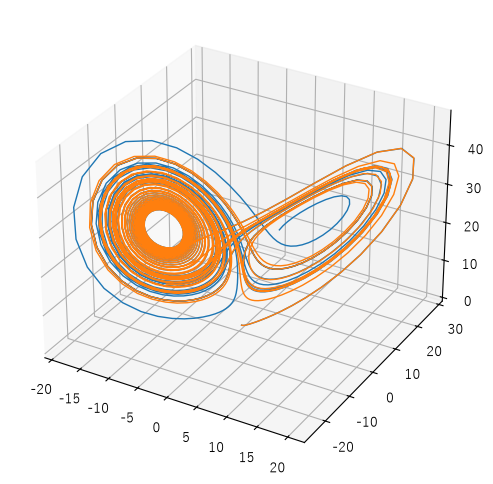

In [8]:
from scipy.integrate import odeint


def lorenz(t, w, p, r, b):  #❶
    """位置 w での dx/dt, dy/dt, dz/dt を返す。"""
    x, y, z = w.tolist()
    return p * (y - x), x * (r - z) - y, x * y - b * z


t = np.arange(0, 30, 0.02)
track_a = odeint(lorenz, (0.0, 1.00, 0.0), t, args=(10.0, 28.0, 3.0), tfirst=True)  #❷
track_b = odeint(lorenz, (0.0, 1.01, 0.0), t, args=(10.0, 28.0, 3.0), tfirst=True)  #❸

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(1, 1, 1, projection="3d")
ax.plot(track_a[:, 0], track_a[:, 1], track_a[:, 2], lw=1)
ax.plot(track_b[:, 0], track_b[:, 1], track_b[:, 2], lw=1)
plt.show()

図から分かるように、初期値が 0.01 違うだけで、2 つの軌跡はまったく別のものになります。

`odeint()` では、状態を記録する時刻を自分で指定します。新しい `solve_ivp()` では、積分のアルゴリズムが必要な時刻を自動で決めます。次のプログラムは `solve_ivp()` で同じ系を解きます。

最初の 3 つの引数は、微分値を返す関数、積分区間、初期状態です。`method` は積分のアルゴリズムで、`RK45` は古典的なルンゲ・クッタ法です。戻り値は `OdeResult` で、`t` と `y` が時刻と状態です。`dense_output=True` にすると、`sol` 属性に補間用のオブジェクトが入り、任意の時刻の状態を計算できます。

In [9]:
from scipy.integrate import solve_ivp

res = solve_ivp(
    lorenz, (0, 30), (0, 1, 0), args=(10, 28, 3), method="RK45", dense_output=True
)
print("segments = {}, t length={}".format(res.sol.n_segments, len(res.t)))

segments = 348, t length=349


`OdeSolution` オブジェクトを呼ぶと、任意の時刻の状態が計算できます。ここでは区間を 20000 点に分けて補間し、積分の点と並べて描きます。滑らかな曲線が補間の結果で、丸い点は `solve_ivp()` が計算した状態です。

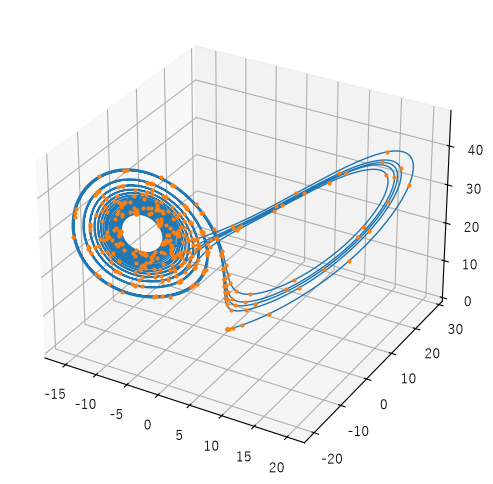

In [10]:
t = np.linspace(0, 30, 20000)
x, y, z = res.sol(t)

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(1, 1, 1, projection="3d")
ax.plot(x, y, z, lw=1)
x2, y2, z2 = res.y
ax.plot(x2, y2, z2, "o", ms=2)
plt.show()

## 質量-ばね-ダンパ系

次の図のような質量-ばね-ダンパ系をシミュレーションし、PID コントローラで位置を制御します。系の式は次のとおりです。

$$m \ddot{x} + b \dot{x} + k x = F$$

$x$ は変位、$\dot{x}$ は速度、$\ddot{x}$ は加速度です。$m$ は質量、$b$ はダンパーの係数、$k$ はばねの係数、$F$ は外から加える力です。

2 階の微分方程式なので、`odeint()` で解くには 1 階の連立方程式に直します。

$$
\begin{align*}
\dot{x} &= u \\ 
\dot{u} &= (F - k x - b u)/m
\end{align*}
$$

$x$ が変位、$u$ が速度で、この 2 つが系の状態です。

![質量-ばね-ダンパーシステム](images/mass_spring_damper.png)

次の `MassSpringDamper` クラスは、パラメータ `m`、`k`、`b` と力 `force` を持ち、`diff()` で変位と速度の微分を計算します。

In [11]:
class MassSpringDamper:
    def __init__(self, m, k, b, force=0):
        self.m, self.k, self.b = m, k, b
        self.force = force

    def diff(self, t, status):
        """状態 (x, u) の微分を返す。"""
        x, u = status
        dx = u
        du = (self.force - self.k * x - self.b * u) / self.m
        return [dx, du]

`odeint()` でこの系を解きます。初期の変位と速度はどちらも 0 で、力は常に 1 です。図のように、約 2 秒で変位 0.05 に落ち着きます。

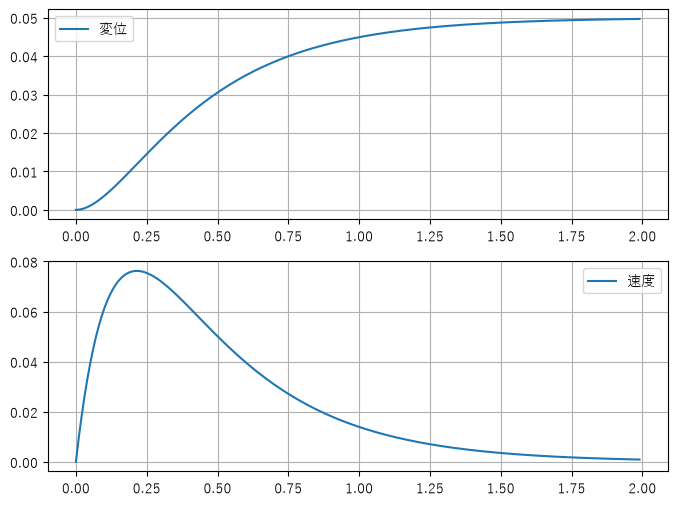

In [12]:
m, k, b, force = 1.0, 20.0, 10.0, 1.0
open_system = MassSpringDamper(m, k, b, force)
init_status = 0.0, 0.0
t = np.arange(0, 2, 0.01)
result = odeint(open_system.diff, init_status, t, tfirst=True)

fig, axes = plt.subplots(2, 1, figsize=(8, 6))
axes[0].plot(t, result[:, 0], label="変位")
axes[1].plot(t, result[:, 1], label="速度")
for ax in axes:
    ax.legend()
    ax.grid()
plt.show()

外から加える力 $F$ を調整すれば、もっと速く変位 1.0 で止められます。そのために PID コントローラを使います。次の図が PID 制御の構成です。

![PID 制御システム](images/PID-system.svg)

Setpoint が目標の値で、この例では目標の変位です。Process が制御対象で、Output がその出力、つまり実際の変位です。両者の差 Error が PID コントローラへの入力になります。PID コントローラは 3 つの部分からなります。

* P：比例項。出力は誤差に比例する。
* I：積分項。出力は誤差の積分に比例する。
* D：微分項。出力は誤差の微分に比例する。

3 つの項の和がコントローラの出力で、この例では質量に加える力 $F$ です。

次の `PIDControl` クラスは、`kp`、`ki`、`kd` と目標変位 `x_ref` を持ちます。`control_force()` は制御力を計算し、状態 `status` は変位、速度、誤差の積分の 3 つです。制御力は、誤差、誤差の積分、誤差の微分にそれぞれゲインを掛けて足したものです。誤差の微分は、速度に -1 を掛けたものです。

In [13]:
class PIDControl:
    def __init__(self, kp, ki, kd, x_ref):
        self.kp, self.ki, self.kd = kp, ki, kd
        self.x_ref = x_ref

    def control_force(self, status):
        x, u, eint = status
        self.err = self.x_ref - x
        force = self.kp * self.err + self.ki * eint + self.kd * (-u)
        return force

次の `System` クラスは、`MassSpringDamper` と `PIDControl` をまとめ、`diff()` で変位、速度、誤差の積分の微分を返します。

In [14]:
class System:
    def __init__(self, m, k, b, kp, ki, kd, x_ref):
        self.target = MassSpringDamper(m, k, b)
        self.pid = PIDControl(kp, ki, kd, x_ref)

    def diff(self, t, status):
        x, u, eint = status
        self.target.force = self.pid.control_force(status)
        dx, du = self.target.diff(t, [x, u])
        return dx, du, self.pid.err

`odeint()` で、PID 制御した系をシミュレーションします。各時刻の状態を計算したあと、その状態を `control_force()` に渡して制御力を求めます。

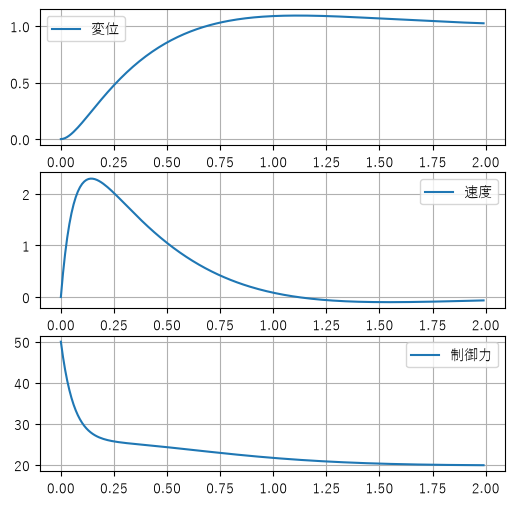

In [15]:
system = System(m=m, k=k, b=b, kp=50, ki=100, kd=10, x_ref=1)
init_status = 0.0, 0.0, 0.0
dt = 0.01
t = np.arange(0, 2, dt)
res_pid = odeint(system.diff, init_status, t, tfirst=True)

x, v, eint = res_pid.T
force = system.pid.control_force(res_pid.T)


def plot_result(t, x, v, force):
    fig, axes = plt.subplots(3, 1, figsize=(6, 6))
    for ax in axes:
        ax.grid(True)
    axes[0].plot(t, x, label="変位")
    axes[0].legend(loc="best")
    axes[1].plot(t, v, label="速度")
    axes[1].legend(loc="best")
    axes[2].plot(t, force, label="制御力")
    axes[2].legend(loc="best")
    plt.show()


plot_result(t, x, v, force)

PID の 3 つのパラメータを調整すると、制御の結果が良くなります。前の章の `optimize` を使って、パラメータを自動で探せます。そのためには、制御の結果を評価する関数を用意します。目標は、できるだけ速く変位 1.0 で止めることなので、最初の 2 秒間の誤差の二乗和を評価にします。この値が小さいほど、制御がうまくいっています。

In [16]:
%%time


def pid_control_system(kp, ki, kd, dt, m=1.0, k=20.0, b=10.0, tend=2):
    """PID パラメータを渡して、変位・速度・制御力を返す。"""
    system = System(m=m, k=k, b=b, kp=kp, ki=ki, kd=kd, x_ref=1)
    init_status = 0.0, 0.0, 0.0
    t = np.arange(0, tend, dt)
    res = odeint(system.diff, init_status, t, tfirst=True)
    force = system.pid.control_force(res.T)
    return t, res.T, force


def eval_func(k):
    kp, ki, kd = k
    t, (x, v, eint), force = pid_control_system(kp, ki, kd, 0.01)
    return np.sum((x - 1.0) ** 2)


kwargs = {"method": "L-BFGS-B", "bounds": [(10, 1000), (10, 1000), (1, 200)]}

opt_k = optimize.basinhopping(
    eval_func, (10, 10, 10), niter=10, minimizer_kwargs=kwargs
)
print(opt_k.x, opt_k.fun)

[441.74663608 148.10991408  10.65184632] 5.277549881734096
CPU times: total: 6.55 s
Wall time: 6.78 s


見つかったパラメータで、もう一度シミュレーションします。制御を始めて 0.5 秒で、変位がほぼ 1.0 で安定しています。

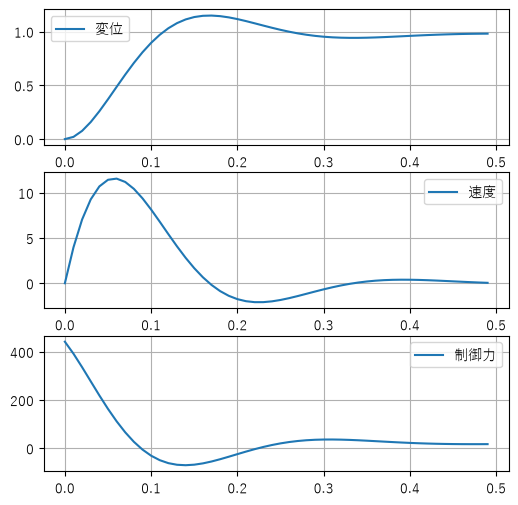

In [17]:
t, (x, v, eint), force = pid_control_system(*opt_k.x, dt=0.01, tend=0.5)
plot_result(t, x, v, force)

## 懸垂線のシミュレーション

ニュートンの運動方程式で、懸垂線をシミュレーションできます。懸垂線を、ばねでつないだ質点の列と考えます。各質点には重力と、左右のばねの力が働きます。動くときには、速度に比例する抵抗力も働きます。両端の質点は固定し、力を計算しないので、加速度はいつも 0 です。

各質点は位置と速度の 4 つの状態を持つので、N 個の質点で 4N 個の状態になります。次の `diff_status()` が状態の微分を返し、`solve_ivp()` で積分します。時間が十分たつと、抵抗力によって各質点は釣り合いの位置に落ち着きます。

a= 0.337 length= 1.377 solve length= 1.410


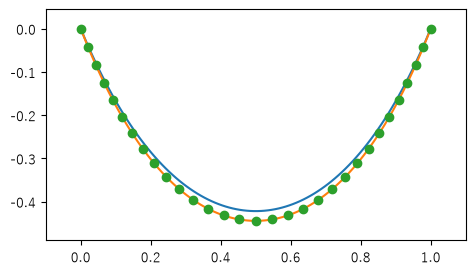

In [18]:
import math


def catenary(x, a):
    return a * np.cosh((x - 0.5) / a) - a * np.cosh((-0.5) / a)


def catenary_length(a):
    def fs(x):
        return (math.sinh((x - 0.5) / a) ** 2 + 1) ** 0.5

    return integrate.quad(fs, 0, 1)[0]


a = 0.35
length = catenary_length(a)
N = 31
dump = 0.2          # 減衰係数
k = 100.0           # ばね定数
l = length / (N - 1)  # ばねの自然長
g = 0.01            # 重力加速度

x0 = np.linspace(0, 1, N)
y0 = np.zeros_like(x0)
vx0 = np.zeros_like(x0)
vy0 = np.zeros_like(x0)


def diff_status(t, status):
    """質点の列の状態 (x, y, vx, vy) の微分を返す。"""
    x, y, vx, vy = status.reshape(4, -1)
    dvx = np.zeros_like(x)
    dvy = np.zeros_like(x)
    dx = vx
    dy = vy

    s = np.s_[1:-1]     # 両端は固定なので、内側だけ計算する

    len_left = np.sqrt((x[s] - x[:-2]) ** 2 + (y[s] - y[:-2]) ** 2)
    len_right = np.sqrt((x[s] - x[2:]) ** 2 + (y[s] - y[2:]) ** 2)
    stretch_left = (len_left - l) / len_left     # 自然長からの伸び
    stretch_right = (len_right - l) / len_right
    dvx[s] = -vx[s] * dump - (x[s] - x[:-2]) * k * stretch_left - (x[s] - x[2:]) * k * stretch_right
    dvy[s] = -vy[s] * dump - (y[s] - y[:-2]) * k * stretch_left - (y[s] - y[2:]) * k * stretch_right + g
    return np.r_[dx, dy, dvx, dvy]


status0 = np.r_[x0, y0, vx0, vy0]

r = integrate.solve_ivp(diff_status, (0, 50), status0)
x, y, vx, vy = r.y[:, -1].reshape(4, -1)

r, e = optimize.curve_fit(catenary, x, -y, [1])
print(
    "a={:6.3f} length={:6.3f} solve length={:6.3f}".format(
        r[0], length, catenary_length(r[0])
    )
)

fig = plt.figure(figsize=(7, 3))
x2 = np.linspace(0, 1, 100)
plt.plot(x2, catenary(x2, a))
plt.plot(x2, catenary(x2, r[0]))
plt.plot(x, -y, "o")
plt.margins(0.1)
plt.subplots_adjust(left=0.3)
plt.show()

図の丸い点が各質点の最終位置です。赤い曲線は、その位置に懸垂線の式を当てはめたものです。青い曲線は、ばねが自然長のときの懸垂線です。最終状態を青い曲線に近づけるには、ばね定数を大きく、重力加速度を小さくします。そうすると、各ばねが自然長に近くなります。前の係数を変えて、試してみてください。

本書には、懸垂線のアニメーションのプログラムもあります。スライダーでパラメータを変え、動きがどう変わるかをその場で見られます。このプログラムは、`solve_ivp()` が内部で使う `integrate.RK45` の `step()` で時間を少しずつ進めています。

### 懸垂線の境界値問題

懸垂線は、次の 2 つの微分方程式を解いても求められます。$(x, y)$ は曲線上の点、$a$ は形を決めるパラメータです。

$$
\begin{align}
\frac {dy}{dx}&=\frac {s}{a}
\\
\frac {ds}{dx}&=\sqrt {1+\left({\dfrac {dy}{dx}}\right)^{2}}
\end{align}
$$

両端の高さは決まっているので、これは境界値問題です。`solve_bvp()` で解けます。

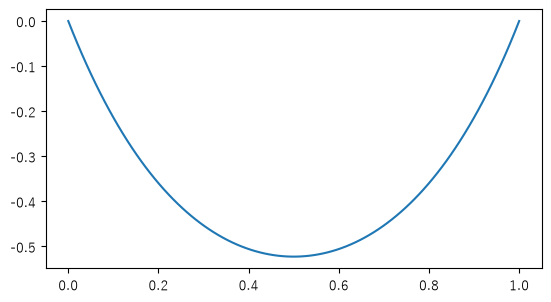

In [19]:
a = 0.3

tmp = []


def catenary_func(x, variables):
    """懸垂線の微分方程式。variables は (y, s)。"""
    tmp.append(variables.copy())
    y, s = variables
    dy = s / a
    ds = (1 + dy**2) ** 0.5
    return np.vstack((dy, ds))


def bc_func(vars_a, vars_b):
    """両端の y が 0 という条件。"""
    ya, sa = vars_a
    yb, sb = vars_b
    return [ya - 0, yb - 0]


x = np.linspace(0, 1, 10)
variables = np.zeros((2, len(x)))
res = integrate.solve_bvp(catenary_func, bc_func, x, variables)

x2 = np.linspace(0, 1, 100)
y2, s2 = res.sol(x2)

fig, ax = plt.subplots()
ax.set_aspect("equal")
ax.plot(x2, y2)
plt.show()

## まとめ

* 定積分は `quad()` で計算する。戻り値は積分値と誤差の推定値。
* 2 重積分は `dblquad()`、3 重積分は `tplquad()` を使う。y の区間は関数で渡す。
* 常微分方程式は `odeint()` か `solve_ivp()` で解く。`solve_ivp()` は時刻を自動で選び、`dense_output` で補間もできる。
* 2 階の微分方程式は、1 階の連立方程式に直してから解く。
* PID 制御のパラメータは、応答を評価する関数を書いて `optimize` で探せる。
* ばねでつないだ質点の系で懸垂線をシミュレーションでき、`solve_bvp()` で境界値問題としても解ける。